
**Created by:**

__Viktor Varga__

<br>
<img src="../_files/ik_logo.png" style="display:inline-block" width='40%'>
<hr>

# Visualizing hypothesis functions learned by neural networks


In this notebook we demonstrate how the complexity of classification decision surfaces learned by neural networks grows as we increase the number of neurons in fully connected layers. By increasing the number of neurons in a layer we increase the dimensionality of the vector space; in other words, our decision surfaces can be learned in a higher-dimensional space, which can be beneficial.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn.datasets
import torch
import torch.nn as nn

First, let’s generate a two-variable dataset with two label categories where the samples from different categories are not linearly separable in two dimensions; that is, there is no hyperplane (in this case, a line) that separates the samples of different categories without error.


Training samples, input shape:  (100, 2)
Training samples, labels shape: (100,)


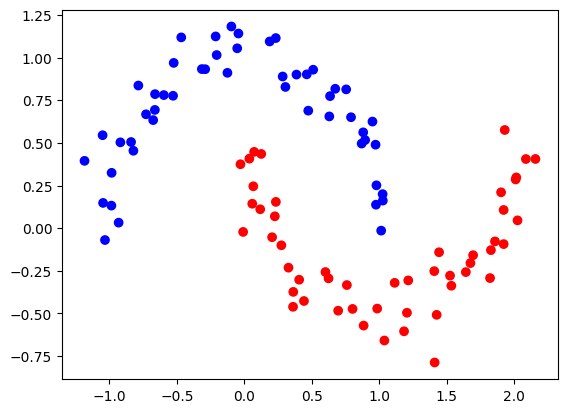

In [ ]:
xs_train, ys_train = sklearn.datasets.make_moons(n_samples=100, noise=0.1)
print("Training samples, input shape: ", xs_train.shape)                    # 2D samples: [[x1, x2]]
print("Training samples, labels shape:", ys_train.shape)                    # labels of samples: 0 or 1
plt.scatter(xs_train[:,0], xs_train[:,1], c=['r' if y == 1 else 'b' for y in ys_train])  # red for label 1, blue for 0
plt.show();

In the following, we define a new class and a few helper functions.

First, we define our neural network model, the `BinaryClassificationModel` class, which is a subclass of `torch.nn.Module`. It implements a standard Multi-layer Perceptron (MLP) consisting of fully connected layers interleaved with activation functions. In the constructor we can specify the number of layers, the number of neurons in the hidden layers, and the corresponding activation functions. The first layer always operates on two input variables, since our dataset is two-dimensional: this makes it easy to plot both the samples and the learned hypothesis function / decision surface. The last layer always predicts a single label variable, and we apply a sigmoid activation to it because we are learning a binary classification problem - so the plotted hypothesis function represents the predicted probabilities. Naturally, the class implements the `forward()` method, which evaluates the hypothesis function, i.e., produces predictions for the provided points.


In [ ]:
class BinaryClassificationModel(nn.Module):

  '''
  Simple MLP neural network model with fully-connected layers for binary classification.
  '''

  def __init__(self, n_layers, n_neurons_per_layer, intermediate_activations='sigmoid'):
    super().__init__()
    assert n_layers < 10, "Too many layers!"
    assert (n_layers == 1) or (n_neurons_per_layer < 1000), "Too many neurons!"   # if n_layers == 1, 'n_neurons_per_layer' is not used
    assert intermediate_activations in ['sigmoid', 'tanh', 'relu']
    activations_classes_dict = {'sigmoid': nn.Sigmoid, 'tanh': nn.Tanh, 'relu': nn.ReLU}
    intermediate_activation_class = activations_classes_dict[intermediate_activations]

    layers_ls = []
    for layer_idx in range(n_layers):
      layer_input_size = 2 if layer_idx == 0 else n_neurons_per_layer
      layer_output_size = 1 if layer_idx == n_layers-1 else n_neurons_per_layer
      layers_ls.append(nn.Linear(layer_input_size, layer_output_size))
      if layer_idx < n_layers-1:    # if not last layer, apply 'intermediate_activations'
        layers_ls.append(intermediate_activation_class())

    layers_ls.append(nn.Sigmoid())    # apply last activation: strictly sigmoid, as we are doing binary classification
    self.layers = nn.Sequential(*layers_ls)

  def forward(self, x):
      return self.layers(x)


In the next cell we define the functions used to train the network.

In addition to the BCE loss, we also want to measure prediction accuracy on the training set. For this we define the `accuracy_binary_torch(ys_pred, ys_true)` function, which computes the accuracy of `ys_pred` (containing predicted label probabilities) with respect to the true binary labels `ys_true`. The function is decorated with `@torch.no_grad()`, which tells PyTorch not to track gradients for tensors created inside the function body. We use accuracy only for monitoring; we do not optimize it with gradient-based methods (the BCE loss serves that purpose - we minimize only that). Disabling gradient tracking here saves time and memory.

Next we define the `train_model_one_epoch(..)` function, which trains the given model on the given training data for a single *epoch*. Training consists of multiple epochs. During one epoch we iterate over the entire training set exactly once: we enumerate the training data in batches and repeat the forward-propagation and backpropagation steps for each batch. We compute the model’s predictions for each batch, compare them to the true labels in that batch, compute the loss, and then update the model parameters based on the derivative of the loss. The `train_model_one_epoch(..)` function returns the training loss and accuracy measured during the epoch.

Our third function is `train_model_until_convergence(..)`, which trains the given model on the given training data for as many epochs as needed until the training loss no longer decreases substantially. That is, we do not use validation or early stopping, because we *intentionally* overfit the network to the training data. In general this would not be very useful; here, however, we want to examine how well the network can learn closely fitting hypothesis functions and decision surfaces on synthetic data - not how well those surfaces generalize to unseen data.


In [ ]:
@torch.no_grad()                                # no_grad decorator sets requires_grad=False to all new tensors created in function body
def accuracy_binary_torch(ys_pred, ys_true):
  '''
  Accuracy function over torch tensors; Only for binary classification, does not work for multiclass :(((((
  Parameters:
    ys_pred: (<t_shape>) fl32; in range (0,1)
    ys_true: (<t_shape>) fl32; in {0, 1}
  Returns:
    (float); the binary accuracy
  '''
  return torch.mean((torch.round(ys_pred) == ys_true).to(torch.float32))    # taking mean of bool dtype arrays works in numpy, not in torch


def train_model_one_epoch(model, xs_train_t, ys_train_t, batch_size, loss_fn, optimizer):
  '''
  Trains the model for a single epoch (iterates training data tensors once).
  Parameters:
    model: torch.nn.Module subclass instance
    xs_train_t: torch.Tensor(n_tr_samples, 2) fl32; dataset sample point coordinates
    ys_train_t: torch.Tensor(n_tr_samples,) fl32; dataset sample classes (0 or 1)
    batch_size: int
    loss_fn: callable, e.g. torch.nn.BCELoss()
    optimizer: torch.optim.Optimizer subclass instance, e.g., torch.optim.RMSprop(...)
  Returns:
    train_loss_mean: float (torch.float32 scalar); mean loss for epoch measured on the training set
    train_accuracies_mean: float (torch.float32 scalar); mean accuracy for epoch measured on the training set
  '''
  assert batch_size >= 1

  train_losses = []
  train_accuracies = []
  model.train()
  for sample_offset in range(0, xs_train_t.shape[0], batch_size):
    sample_end_offset = min(sample_offset + batch_size, xs_train_t.shape[0])
    xs_train_batch = xs_train_t[sample_offset:sample_end_offset, :]
    ys_train_batch = ys_train_t[sample_offset:sample_end_offset, None]   # (batch_size,) -> (batch_size, 1) to fit prediction shapes in loss_fn, accuracy

    optimizer.zero_grad()
    ys_pred_batch = model(xs_train_batch)
    loss_batch = loss_fn(ys_pred_batch, ys_train_batch)
    loss_batch.backward()
    optimizer.step()
    accuracy_batch = accuracy_binary_torch(ys_pred_batch, ys_train_batch)

    train_losses.append(loss_batch.detach())       # detach from computational graph to reduce memory usage, as we don't need to keep gradient for previous batches
    train_accuracies.append(accuracy_batch)        # accuracy_batch is already detached from computatuional graph as this tensor was created in a @torch.no_grad() block

  train_losses = torch.tensor(train_losses)           # taking mean of lists works in numpy, not in torch: explicitly creating tensor from list of floats
  train_accuracies = torch.tensor(train_accuracies)   # taking mean of lists works in numpy, not in torch: explicitly creating tensor from list of floats
  train_loss_mean = torch.mean(train_losses)
  train_accuracy_mean = torch.mean(train_accuracies)
  return train_loss_mean, train_accuracy_mean


def train_model_until_convergence(model, xs_train, ys_train):
  '''
  Overfits the model to the training data. Training is continued until convergence.
  Parameters:
    model: torch.nn.Module subclass instance
    xs_train: ndarray(n_tr_samples, 2) fl32; dataset sample point coordinates
    ys_train: ndarray(n_tr_samples,) fl32; dataset sample classes (0 or 1)
  '''
  N_MAX_EPOCHS = 10000
  LOGGING_FREQ_N_EPOCHS = 1000
  BATCH_SIZE = 512
  LEARNING_RATE = 0.01

  xs_train_t = torch.from_numpy(xs_train).to(dtype=torch.float32)   # numpy.ndarray -> torch.Tensor
  ys_train_t = torch.from_numpy(ys_train).to(dtype=torch.float32)   # numpy.ndarray -> torch.Tensor
  loss_fn = torch.nn.BCELoss()
  optimizer = torch.optim.RMSprop(model.parameters(), lr=LEARNING_RATE)

  # check training accuracy once in while and if there is no improvement since last check, end training
  #    training loss can improve for a very long time, so we check accuracy (there are only 100 training samples - accuracy cannot improve indefinitely)
  tr_acc_prev_check = 0.         # init to zero
  for epoch_idx in range(N_MAX_EPOCHS):

    tr_loss_in_epoch, tr_acc_in_epoch = train_model_one_epoch(model, xs_train_t, ys_train_t, BATCH_SIZE, loss_fn, optimizer)

    if epoch_idx % LOGGING_FREQ_N_EPOCHS == 0:
      print(f'Metrics at epoch # {epoch_idx} - BCE training loss: {tr_loss_in_epoch}, training accuracy: {tr_acc_in_epoch} ')
      if tr_acc_prev_check > tr_acc_in_epoch*0.999:
        print(f'Ending training at epoch # {epoch_idx}, as there was no significant improvement since last check.')
        break
      tr_acc_prev_check = tr_acc_in_epoch


Finally, we define the `predict_grid_and_plot(..)` function, which we use to visualize the hypothesis function and decision surface represented by a trained neural network. To do this, we generate a grid over roughly the region of the input space where the training data lies. The grid points form our test set. We evaluate the network at each grid point, using the grid coordinates as the input variables, and record the predictions. If we plotted these predictions on a third axis (pointing outwards perpendicularly from your display) and used a sufficiently dense grid, we would obtain a relatively smooth surface—the learned hypothesis function. Here we visualize it in 2D by mapping prediction values to colors, i.e., we plot a heatmap (`matplotlib.pyplot.pcolormesh`) of the hypothesis function over the grid. We also overlay the coordinates of the original training examples (`matplotlib.pyplot.scatter`) and mark the decision boundary defined by the level set *y = 0.5* (`matplotlib.pyplot.contour`).


In [ ]:
@torch.no_grad()
def predict_grid_and_plot(model, xs_train, ys_train, grid_resolution=100):
  '''
  Creates a grid of test samples that span the area where training samples (xs_train) are located.
  Preicts the labels in the gridpoints (in other words, evaluates the learned hypothesis function in the grid points)
  Parameters:
    model: torch.nn.Module subclass instance; the trained model
    xs_train: ndarray(n_tr_samples, 2) fl32; dataset sample point coordinates
    ys_train: ndarray(n_tr_samples,) fl32; dataset sample classes (0 or 1)
  '''
  BATCH_SIZE = 512
  xs_train_t = torch.from_numpy(xs_train).to(dtype=torch.float32)   # numpy.ndarray -> torch.Tensor

  # create a grid over the area between min and max of training sample point coordinates
  x1 = np.linspace(np.amin(xs_train[:,0]), np.amax(xs_train[:,0]), num=grid_resolution)
  x2 = np.linspace(np.amin(xs_train[:,1]), np.amax(xs_train[:,1]), num=grid_resolution)
  xx1, xx2 = np.meshgrid(x1, x2)                                # creating 2D coordinate grids, separately for the two coordinates
  xs_eval = np.stack([xx1, xx2], axis=-1).reshape((-1, 2))      # (n_grid_points, 2)

  xs_eval_t = torch.from_numpy(xs_eval).to(dtype=torch.float32)   # numpy.ndarray -> torch.Tensor
  ys_preds = []

  for sample_offset in range(0, xs_eval_t.shape[0], BATCH_SIZE):
    sample_end_offset = min(sample_offset + BATCH_SIZE, xs_eval_t.shape[0])
    xs_eval_batch = xs_eval_t[sample_offset:sample_end_offset, :]

    ys_pred_batch = model(xs_eval_batch)
    ys_preds.append(ys_pred_batch)

  ys_preds = torch.cat(ys_preds, dim=0)   # concatenate batches of predictions into a single tensor
  ys_preds = ys_preds.reshape((grid_resolution, grid_resolution)).numpy()    # torch.Tensor -> numpy.ndarray for plotting

  plt.figure()
  CS = plt.pcolormesh(xx1, xx2, ys_preds)
  plt.scatter(xs_train[:,0], xs_train[:,1], c=['r' if y == 1 else 'b' for y in ys_train])  # red for label 1, blue for 0
  plt.contour(xx1, xx2, ys_preds, levels=[0.5, 1.5], colors='r')    # mark decision boundary at 0.5 (the other value, 1.5 is dummy only)
  plt.colorbar(CS)
  plt.xlabel("x_1")
  plt.ylabel("x_2")
  plt.title("y")
  plt.show();

We generate a single-layer neural network with a single neuron (no hidden layer). This corresponds to a single (multivariate) logistic regression model. We train the model and plot the learned hypothesis function. It is clear that logistic regression can only learn a linear separation.


Metrics at epoch # 0 - BCE training loss: 0.8564630150794983, training accuracy: 0.33000001311302185 
Metrics at epoch # 1000 - BCE training loss: 0.24798311293125153, training accuracy: 0.8899999856948853 
Metrics at epoch # 2000 - BCE training loss: 0.2479633390903473, training accuracy: 0.8899999856948853 
Ending training at epoch # 2000, as there was no significant improvement since last check.


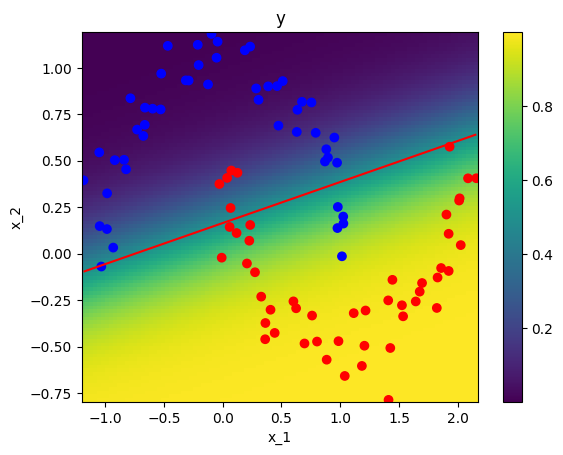

In [ ]:
model_single_neuron = BinaryClassificationModel(n_layers=1, n_neurons_per_layer=None, intermediate_activations='sigmoid')
train_model_until_convergence(model_single_neuron, xs_train, ys_train)
predict_grid_and_plot(model_single_neuron, xs_train, ys_train)


Now we learn the same dataset with a two-layer network. The first layer will have 20 neurons, and the second layer will consist of a single neuron that produces the prediction.


Metrics at epoch # 0 - BCE training loss: 0.825829029083252, training accuracy: 0.1599999964237213 
Metrics at epoch # 1000 - BCE training loss: 0.0003536117437761277, training accuracy: 1.0 
Metrics at epoch # 2000 - BCE training loss: 2.161876864192891e-06, training accuracy: 1.0 
Ending training at epoch # 2000, as there was no significant improvement since last check.


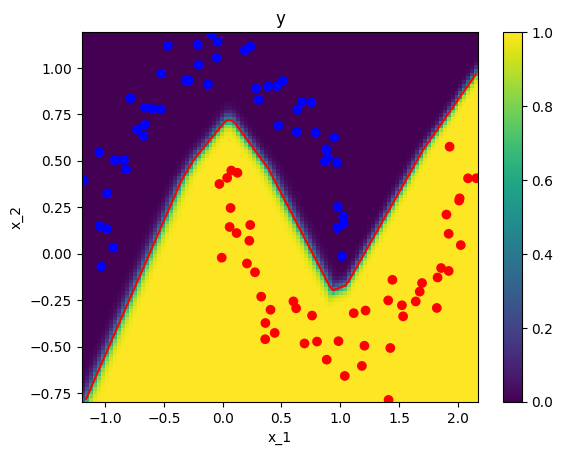

In [ ]:
model_mlp_2layers = BinaryClassificationModel(n_layers=2, n_neurons_per_layer=20, intermediate_activations='relu')
train_model_until_convergence(model_mlp_2layers, xs_train, ys_train)
predict_grid_and_plot(model_mlp_2layers, xs_train, ys_train)


Let’s now generate a dataset that is even harder to classify correctly.


Training samples, input shape:  (500, 2)
Training samples, labels shape: (500,)


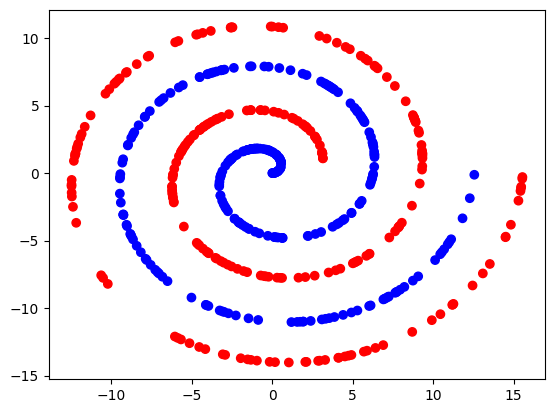

In [ ]:

ys_train2 = np.random.randint(2, size=(500,))
t = 4. * np.pi * (np.random.rand(ys_train2.shape[0]))

radd = np.zeros_like(ys_train2, dtype=np.float32)
radd[ys_train2 == 1] = 3.
xs_train2 = np.stack([(t+radd) * np.cos(t), (t+radd) * np.sin(t)], axis=-1)

print("Training samples, input shape: ", xs_train2.shape)                    # 2D samples: [[x1, x2]]
print("Training samples, labels shape:", ys_train2.shape)                    # labels of samples: 0 or 1

plt.scatter(xs_train2[:,0], xs_train2[:,1], c=['r' if y == 1 else 'b' for y in ys_train2])  # red for label 1, blue for 0
plt.show();


We try to learn to classify the more complex dataset using our previous two-layer network. As you can see, it does not perform very well.


Metrics at epoch # 0 - BCE training loss: 0.8207468390464783, training accuracy: 0.4779999852180481 
Metrics at epoch # 1000 - BCE training loss: 0.5740423202514648, training accuracy: 0.6159999966621399 
Metrics at epoch # 2000 - BCE training loss: 0.5655008554458618, training accuracy: 0.6840000152587891 
Metrics at epoch # 3000 - BCE training loss: 0.5501748919487, training accuracy: 0.6520000100135803 
Ending training at epoch # 3000, as there was no significant improvement since last check.


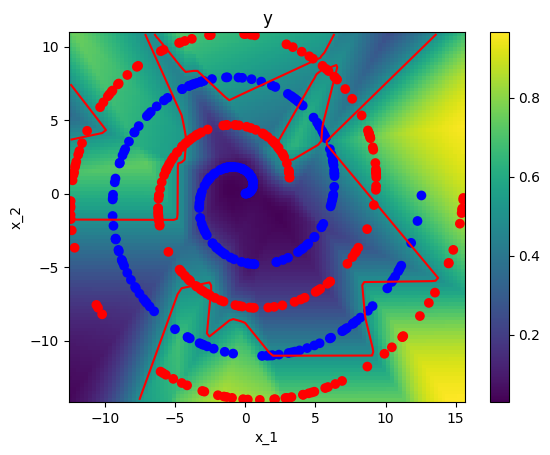

In [ ]:
model_mlp_2layers = BinaryClassificationModel(n_layers=2, n_neurons_per_layer=20, intermediate_activations='relu')
train_model_until_convergence(model_mlp_2layers, xs_train2, ys_train2)
predict_grid_and_plot(model_mlp_2layers, xs_train2, ys_train2)


Let’s add two more layers! The resulting model performs much better; in some places, signs of overfitting are already visible (since we did not use a validation set or early stopping).


Metrics at epoch # 0 - BCE training loss: 0.7495131492614746, training accuracy: 0.42800000309944153 
Metrics at epoch # 1000 - BCE training loss: 0.0002897744416259229, training accuracy: 1.0 
Metrics at epoch # 2000 - BCE training loss: 0.0042596119455993176, training accuracy: 1.0 
Ending training at epoch # 2000, as there was no significant improvement since last check.


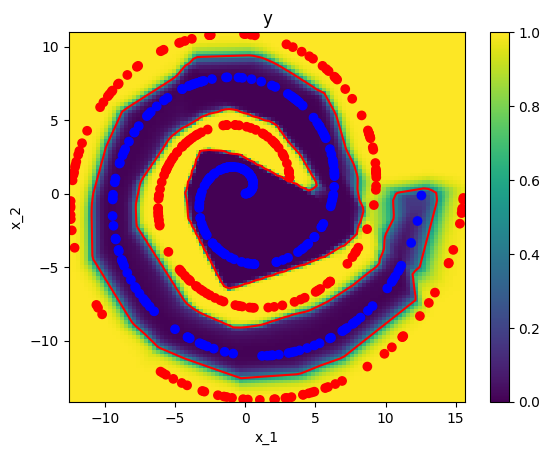

In [ ]:
model_mlp_2layers = BinaryClassificationModel(n_layers=4, n_neurons_per_layer=20, intermediate_activations='relu')
train_model_until_convergence(model_mlp_2layers, xs_train2, ys_train2)
predict_grid_and_plot(model_mlp_2layers, xs_train2, ys_train2)
